# 11 — Sequential intraday forecasts and Kalman-filter exploration

**Result: retain tuned daily LightGBM plus the existing annual 15:30 ridge.** None of the tested sequential or Kalman variants passes the replacement gate. Development log RMSE is 0.45471 for the incumbent, 0.45477 for matched latest-only ridge and 0.45530 for correlated Kalman.

Can earlier checkpoints improve the closing-auction forecast beyond the latest checkpoint alone? This notebook compares simple multi-checkpoint ridge regression, a ridge combination of learned checkpoint signals, and four Kalman variants around the **tuned daily LightGBM anchor**.

The state is the unknown final auction's log residual relative to the daily forecast. It is reinitialised for every stock-day. Checkpoints supply noisy measurements of that same terminal quantity. This is within-day filtering, not smoothing with future observations or updating across stock-days with unobserved closing labels.

All five local checkpoint times are used: **10:30, 12:00, 14:00, 15:00 and 15:30**. Fitting, measurement calibration and filter selection use separate chronological windows before each evaluation year. The existing tuned daily plus annual 15:30 ridge remains an incumbent reference. The new matched latest-only ridge uses the same deliberately frozen component-fitting window as the new sequential candidates.

This is a fresh four-fold exploration on the already inspected 2022–2025 history. Development selection averages 2022–2024 years equally; 2025 is separate retrospective confirmation. The notebook executes the [research implementation](../notebooks/explore_intraday_kalman.py), verifies saved-model reconstruction and timing, and embeds all results. Cached reruns verify existing fitted forecasts. New artifacts are in `outputs/experiments/33_intraday_kalman`.

The execution-control problem is deferred. This notebook does not simulate orders or interpret point forecasts or filter variances as executable liquidity guarantees.

In [1]:
from pathlib import Path
import sys,json,gc,importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display,Markdown
from threadpoolctl import threadpool_limits
ROOT=next(p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents] if (p/'blackrock_data').is_dir())
sys.path.insert(0,str(ROOT))
from notebooks import explore_intraday_kalman as k
import duckdb
sns.set_theme(style='whitegrid',palette='colorblind');plt.rcParams.update({'figure.dpi':110})
pd.set_option('display.max_rows',65);pd.set_option('display.max_columns',14)
pd.set_option('display.float_format',lambda x:f'{x:,.6f}')
RUN=k.OUT
coverage=k.prepare();math_checks=k.verify_math()
versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','duckdb','matplotlib','threadpoolctl']}
k.write_json(RUN/'notebook_environment.json',versions)
display(pd.Series(versions,name='execution version').to_frame())
display(pd.Series(math_checks,name='mathematical checks').to_frame())
display(coverage)
NAMES={'daily':'Tuned daily','latest_ridge':'Matched latest-only ridge','multi_checkpoint_ridge':'Multi-checkpoint ridge',
 'signal_stack_ridge':'Ridge on checkpoint signals','kalman_diagonal':'Kalman: independent errors','kalman_inflated':'Kalman: variance inflation',
 'kalman_correlated':'Kalman: correlated errors','kalman_robust':'Kalman: clipped innovations','incumbent_1530':'Incumbent tuned daily + 15:30 ridge'}

,execution version
numpy,2.4.6
pandas,3.1.1
duckdb,1.5.6
matplotlib,3.11.2
threadpoolctl,3.8.0


,mathematical checks
known_single_measurement,True
missing_measurement_skipped,True
correlated_filter_equals_batch_Gaussian_update,True
ridge_system_matches_original_helper,True


,year,rows,valid_1030,valid_1200,valid_1400,valid_1500,valid_1530
0,2021,320270,319649,320010,320161,320198,320214
1,2022,327355,326373,326861,327074,327125,327156
2,2023,316159,315836,315980,316068,316080,316091
3,2024,312482,312417,312457,312476,312479,312479
4,2025,304172,304136,304152,304170,304171,304171


## The latent quantity and the observations

Let $r=\log(1+A)-\log(1+D)$, where $D$ is the tuned daily forecast and $A$ is the eventual auction volume. The filter estimates $r$ as checkpoint information arrives. Each checkpoint ridge supplies a measurement $m_j$, its predicted residual around the same daily anchor.

The measurement model is calibrated on historical out-of-time component predictions:

$$r\sim(\mu,P_0),\qquad m_j=a_j+H_jr+\epsilon_j,\qquad \operatorname{Cov}(\epsilon)=R.$$

The loading $H_j$ matters: a regularised regression prediction is not automatically an unbiased unit-loading observation of the true residual. The intercept, loading, prior variance and measurement covariance are fitted from calibration labels that precede evaluation. They are fixed during the forecast year.

For the static terminal target, the main filter has $Q=0$. Its state does not assert that the final auction volume physically changes as the session unfolds. A diagonal-noise sensitivity adds process-variance inflation per elapsed hour to let later signals move the estimate more strongly. That is a modelling sensitivity, not a direct measurement of how auction volume evolves.

The standard scalar update for an independent observation is

$$K_j=\frac{P^-_jH_j}{H_j^2P^-_j+R_j},\qquad
\hat r_j=\hat r^-_j+K_j(m_j-a_j-H_j\hat r^-_j).$$

The state-space recursion follows [Kalman (1960), A New Approach to Linear Filtering and Prediction Problems](https://www.cs.unc.edu/~welch/kalman/media/pdf/Kalman1960.pdf). The observation construction and historical calibration here are specific to our auction experiment. Linear-Gaussian optimality depends on its assumptions; it is not an unconditional optimality claim for these data.

## Why we explicitly model correlated checkpoint errors

Cumulative volume at 15:30 contains much of the volume already seen at noon. The learned checkpoint residuals also share the daily inputs and anchor. Independent measurement errors can therefore count overlapping information repeatedly and make the state variance shrink too quickly.

The correlated filter estimates the full error covariance, then shrinks it toward its diagonal for stability. It causally whitens measurements with a Cholesky factor before scalar updates. Each whitened observation uses only observations available at or before that time. The implementation is checked against a direct Gaussian conditional update, including missing measurements and future-value perturbations.

| Candidate | What changes |
| --- | --- |
| Diagonal Kalman | Treats checkpoint measurement errors as independent; searches prior scales 0.5, 1 and 2 |
| Variance-inflated Kalman | Diagonal errors, with variance-inflation fractions 0.01, 0.1 or 0.5 of prior variance per hour |
| Correlated Kalman | Full covariance with diagonal shrinkage 0, 0.25, 0.5 or 0.75 and prior scales 0.5, 1 or 2 |
| Robust Kalman | Correlated errors with shrinkage 0.25/0.75 and innovations clipped at 2.5/4 predicted standard deviations |
| Latest-only ridge | The current checkpoint's 73 sources; matched frozen-window control |
| Multi-checkpoint ridge | Common daily sources plus current and historical fields for every observed checkpoint prefix |
| Signal-stack ridge | A regularised regression on learned checkpoint residuals and missing flags |

Innovation clipping is a sensitivity: it can protect against a bad observation but can also suppress a real auction spike. The grid is fixed before scoring the evaluation years. No test-year target enters the observation stream.

## Chronological fitting: four historical windows

For evaluation year Y, every daily anchor was already generated out of time. The new correction layers follow this protocol:

| Stage | Historical window | Purpose |
| --- | --- | --- |
| Component tuning fit | From January 2021 through March Y−1 | Fit checkpoint and multi-checkpoint ridge coefficients for the penalty search |
| Component validation | April–June Y−1 | Select each ridge penalty from 1e−7 through 1e−1 |
| Frozen component refit | From January 2021 through June Y−1 | Fit the checkpoint means actually used in calibration and evaluation |
| Measurement calibration | July–September Y−1 | Estimate prior, loadings and measurement covariance using out-of-time predictions |
| Meta validation | October–December Y−1 | Select each filter family's settings and signal-stack penalties |
| Final meta calibration | July–December Y−1 | Re-estimate measurement statistics and stack coefficients after selection; checkpoint models stay frozen |
| Evaluation | Year Y | Apply only fitted historical objects and currently available checkpoint inputs |

Caps are 250k tuning, 120k component validation and 350k frozen component refit rows. Calibration and meta-validation use the complete corresponding quarters. Training sample keys and dates are saved.

The first fold therefore fits means on January–June 2021, calibrates on Q3 2021 and selects filter settings on Q4 2021. This uses less recent component fitting history than the incumbent annual ridge, which refits through December. The matched latest-only control shares the frozen window, so it isolates the benefit of earlier checkpoints within this experiment. A replacement must also beat the existing incumbent before changing our main recommendation.

Each filter family's hyperparameters are chosen on historical **15:30 log RMSE** and then used along the full within-day path. Each direct ridge horizon selects its own penalty historically. Missing latest inputs return daily in the latest-only control. Sequential methods can retain earlier observations; if all observations so far are missing they return the exact daily forecast. The availability sensitivity separately reports complete-checkpoint rows.

In [2]:
# Compare noon/15:30 availability with the independently audited earlier studies.
for time,tag,study in [('12:00','1200','20_intraday_noon'),('15:30','1530','19_intraday_1530')]:
    old=pd.read_csv(ROOT/f'outputs/experiments/{study}/coverage_by_year.csv').sort_values('year')
    np.testing.assert_array_equal(coverage[f'valid_{tag}'],old.valid_checkpoint_rows)
    np.testing.assert_array_equal(coverage.rows,old.regular_session_rows)
# Independent pandas reconstruction of prior-only rolling histories for every new time.
con=duckdb.connect(config={'threads':4})
ids=con.execute('SELECT DISTINCT permno FROM read_parquet(?) ORDER BY permno LIMIT 16',[str(RUN/'panels/wide_panel.parquet')]).df().permno.tolist()
ids=','.join(map(str,ids));history_checks=[]
raw=ROOT/'blackrock_data/stock_intraday/trade_checkpoints/year=*/trade_checkpoints_*.parquet'
for time,tag in zip(k.TIMES,k.TAGS):
    f=con.execute(f"""SELECT p.date,p.permno,p.auction_volume,p.eligible_target,p.is_early_close,
     c.checkpoint_data_found,c.checkpoint_after_market_close,c.cum_volume,c.cum_trade_count
     FROM read_parquet('{k.PANEL}') p LEFT JOIN
     (SELECT * FROM read_parquet('{raw}',union_by_name=true) WHERE checkpoint='{time}') c USING(date,permno)
     WHERE p.permno IN ({ids}) ORDER BY p.permno,p.date""").df()
    valid=f.checkpoint_data_found.fillna(False)&~f.checkpoint_after_market_close.fillna(True)&~f.is_early_close.fillna(True)&f.cum_volume.gt(0)
    f['volume']=f.cum_volume.where(valid);f['trades']=f.cum_trade_count.where(valid)
    f['ratio']=(f.auction_volume/f.cum_volume).where(valid&f.eligible_target)
    for name,operation in [('volume','mean'),('trades','mean'),('ratio','median')]:
        f['prior_'+name]=f.groupby('permno')[name].transform(lambda s:getattr(s.shift(1).rolling(20,min_periods=1),operation)())
    saved=con.execute(f'SELECT * FROM read_parquet(?) WHERE permno IN ({ids})',[str(RUN/f'panels/checkpoint_{tag}.parquet')]).df()
    joined=f.merge(saved,on=['date','permno'],validate='one_to_one')
    for left,right in [('prior_volume','checkpoint_avg_volume20'),('prior_trades','checkpoint_avg_trades20'),('prior_ratio','ratio20_auction_to_checkpoint')]:
        np.testing.assert_allclose(joined[left],joined[right],rtol=1e-10,atol=1e-10,equal_nan=True)
    history_checks.append({'checkpoint':time,'rows':len(joined),'stocks':16,'features':3,'passed':True})
history_checks=pd.DataFrame(history_checks);history_checks.to_csv(RUN/'independent_history_checks.csv',index=False)
display(history_checks);con.close()

,checkpoint,rows,stocks,features,passed
0,10:30,16285,16,3,True
1,12:00,16285,16,3,True
2,14:00,16285,16,3,True
3,15:00,16285,16,3,True
4,15:30,16285,16,3,True


## Fit or reconstruct the four complete evaluation folds

The next cell runs the full fitting procedure when artifacts are absent. With a complete cache it reconstructs every component, stacked and Kalman forecast from saved parameters, checks key alignment, chronological boundaries, finite forecasts and exact all-missing fallback. For 2022 it also changes future measurement values and availability and verifies unchanged prefix estimates. These are filtering operations; future-data smoothing is not used.

In [3]:
with threadpool_limits(limits=4):
    for year in k.YEARS:k.fit_year(year)
    summary=k.summarize()
annual=pd.read_csv(RUN/'annual_metrics.csv')
decision=json.loads((RUN/'decision.json').read_text())
selected=[]
for year in k.YEARS:
    meta=json.loads((RUN/f'models/meta_{year}.json').read_text())
    for family,row in meta['selected'].items():selected.append({'year':year,'method':family,**row['config'],'historical_validation_log_RMSE':row['validation_log_rmse']})
selected=pd.DataFrame(selected);display(selected)
manifest=pd.concat([pd.read_csv(RUN/f'samples/manifest_{year}.csv') for year in k.YEARS],ignore_index=True)
display(manifest[['year','role','rows','first','last']])

2026-11-18T18:19:39.700471+00:00 2022: complete cache found; reconstructed by verify_year


2026-11-18T18:19:45.627711+00:00 2022: model reconstruction, causal prefix, fallback and finite-state checks passed


2026-11-18T18:19:45.629963+00:00 2023: complete cache found; reconstructed by verify_year


2026-11-18T18:19:51.055853+00:00 2023: model reconstruction, causal prefix, fallback and finite-state checks passed


2026-11-18T18:19:51.056745+00:00 2024: complete cache found; reconstructed by verify_year


2026-11-18T18:19:56.633221+00:00 2024: model reconstruction, causal prefix, fallback and finite-state checks passed


2026-11-18T18:19:56.634283+00:00 2025: complete cache found; reconstructed by verify_year


2026-11-18T18:20:02.085417+00:00 2025: model reconstruction, causal prefix, fallback and finite-state checks passed


,year,method,shrinkage,prior_scale,historical_validation_log_RMSE,q_fraction,innovation_clip
0,2022,kalman_diagonal,1.000000,0.500000,0.569955,NaN,NaN
1,2022,kalman_inflated,1.000000,NaN,0.654423,0.010000,NaN
2,2022,kalman_correlated,0.000000,1.000000,0.553360,NaN,NaN
3,2022,kalman_robust,0.250000,NaN,0.554043,NaN,2.500000
4,2023,kalman_diagonal,1.000000,0.500000,0.494042,NaN,NaN
5,2023,kalman_inflated,1.000000,NaN,0.565773,0.010000,NaN
6,2023,kalman_correlated,0.250000,1.000000,0.482716,NaN,NaN
7,2023,kalman_robust,0.250000,NaN,0.481929,NaN,2.500000
8,2024,kalman_diagonal,1.000000,0.500000,0.455049,NaN,NaN
9,2024,kalman_inflated,1.000000,NaN,0.541704,0.010000,NaN


,year,role,rows,first,last
0,2022,component_tune,75727,2021-01-04 00:00:00,2021-03-31 00:00:00
1,2022,component_validation,79435,2021-04-01 00:00:00,2021-06-30 00:00:00
2,2022,component_refit,155162,2021-01-04 00:00:00,2021-06-30 00:00:00
3,2022,meta_calibration,82340,2021-07-01 00:00:00,2021-09-30 00:00:00
4,2022,meta_validation,82768,2021-10-01 00:00:00,2021-12-31 00:00:00
5,2022,test,327355,2022-01-03 00:00:00,2022-12-30 00:00:00
6,2023,component_tune,250000,2021-01-04 00:00:00,2022-03-31 00:00:00
7,2023,component_validation,81168,2022-04-01 00:00:00,2022-06-30 00:00:00
8,2023,component_refit,350000,2021-01-04 00:00:00,2022-06-30 00:00:00
9,2023,meta_calibration,83803,2022-07-01 00:00:00,2022-09-30 00:00:00


## The relationship between checkpoint signals and the terminal residual

The next plots use the final historical calibration for the 2025 fold, ending in December 2024. Measurement loadings show how much a learned checkpoint estimate responds to the underlying residual. The residual correlation matrix is calculated after removing the fitted loading and intercept. It measures overlap beyond their shared association with the target.

Posterior state variances are model-based quantities. Their decrease as observations arrive is a mathematical property of the static Gaussian model, not evidence that empirical forecast coverage is correct. We evaluate that distinction below.

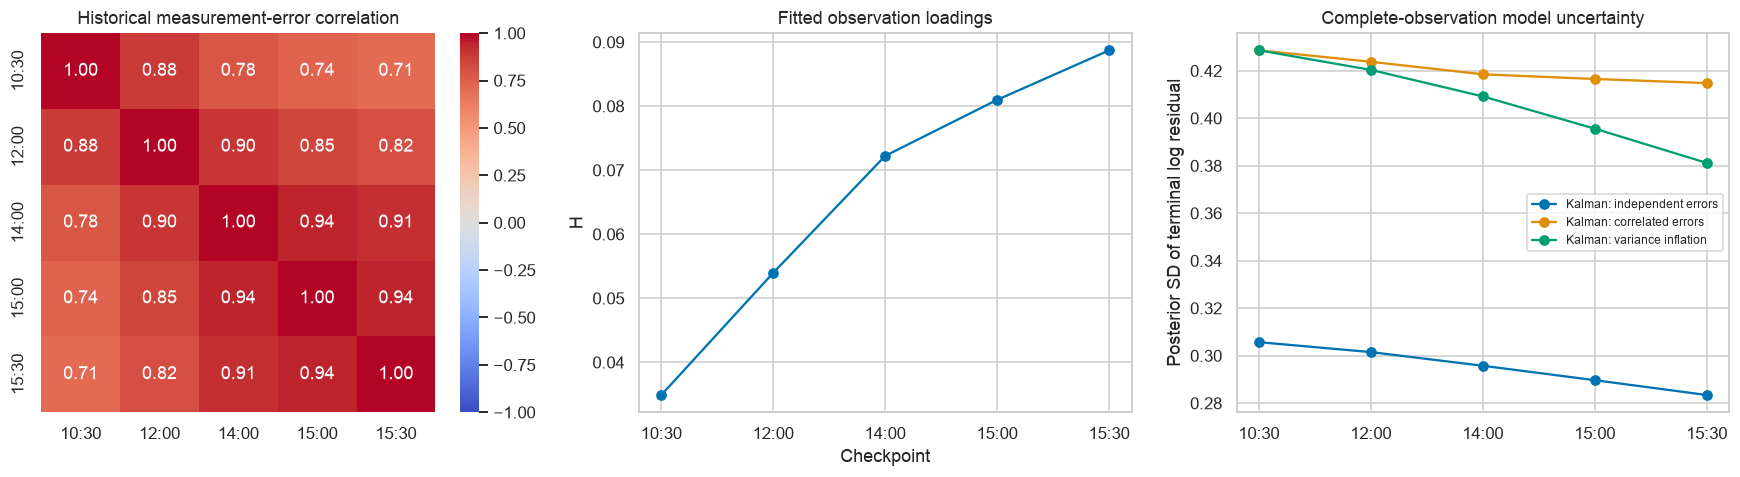

,checkpoint,intercept_a,loading_H,measurement_error_sd
0,10:30,0.026083,0.034887,0.081099
1,12:00,0.026678,0.053973,0.098792
2,14:00,0.023081,0.072234,0.109856
3,15:00,0.022731,0.080985,0.116325
4,15:30,0.022069,0.088712,0.121684


In [4]:
meta=json.loads((RUN/'models/meta_2025.json').read_text());cal=meta['calibration']
R=np.array(cal['R']);sd=np.sqrt(np.diag(R));correlation=R/(sd[:,None]*sd[None,:])
fig,axes=plt.subplots(1,3,figsize=(16,4.5))
sns.heatmap(pd.DataFrame(correlation,index=k.TIMES,columns=k.TIMES),annot=True,fmt='.2f',vmin=-1,vmax=1,cmap='coolwarm',ax=axes[0])
axes[0].set_title('Historical measurement-error correlation')
axes[1].plot(k.TIMES,cal['h'],marker='o');axes[1].set(title='Fitted observation loadings',ylabel='H',xlabel='Checkpoint')
for family in ['kalman_diagonal','kalman_correlated','kalman_inflated']:
    mean,p=k.kalman(np.array(cal['a'])[None,:]+np.array(cal['h'])[None,:]*cal['mu'],cal,meta['selected'][family]['config'])
    axes[2].plot(k.TIMES,np.sqrt(p[0]),marker='o',label=NAMES[family])
axes[2].set(title='Complete-observation model uncertainty',ylabel='Posterior SD of terminal log residual');axes[2].legend(fontsize=8)
plt.tight_layout();plt.show()
display(pd.DataFrame({'checkpoint':k.TIMES,'intercept_a':cal['a'],'loading_H':cal['h'],'measurement_error_sd':sd}))

## Point accuracy along the intraday path

All methods share the regular-session evaluation keys and tuned daily anchor. The latest-only control deliberately uses just the current checkpoint; multi-checkpoint ridge can use every earlier prefix. Signal-stack ridge combines the same learned measurements used by the filters without imposing their state-space covariance structure.

We retain the complete intraday path, rather than reporting only a favorable time. The incumbent was evaluated at 15:30 only and is drawn as a final-time reference. Development metrics are equal-year averages. WAPE here is stock-level absolute share error divided by observed shares.

checkpoint,10:30,12:00,14:00,15:00,15:30
method,,,,,
Tuned daily,0.464074,0.464074,0.464074,0.464074,0.464074
Incumbent tuned daily + 15:30 ridge,NaN,NaN,NaN,NaN,0.454705
Kalman: correlated errors,0.462586,0.460562,0.458765,0.456830,0.455299
Kalman: independent errors,0.463312,0.460906,0.462064,0.466954,0.475699
Kalman: variance inflation,0.462586,0.470229,0.492017,0.524326,0.563178
Kalman: clipped innovations,0.463015,0.461152,0.459320,0.457484,0.455969
Matched latest-only ridge,0.462727,0.460232,0.458414,0.456252,0.454767
Multi-checkpoint ridge,0.462727,0.460203,0.458092,0.456370,0.454808
Ridge on checkpoint signals,0.462514,0.460270,0.458310,0.456302,0.454762


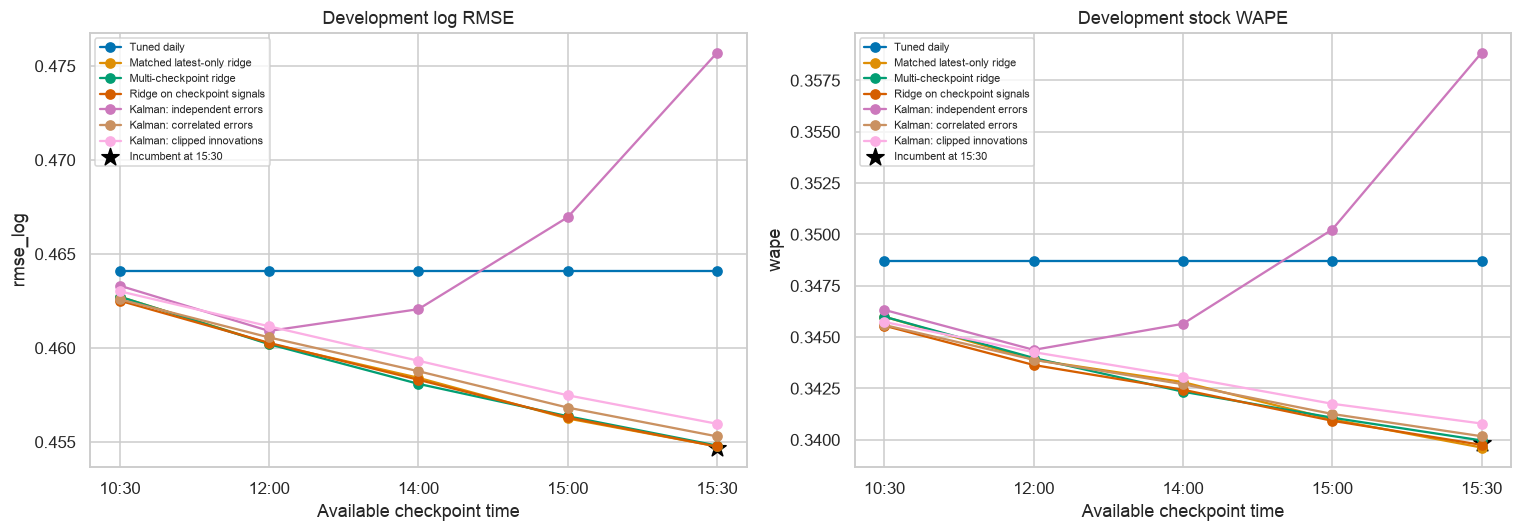

rmse_log                     wape  \
period                              confirmation development confirmation   
method                                                                      
Tuned daily                             0.421605    0.464074     0.323135   
Incumbent tuned daily + 15:30 ridge     0.404183    0.454705     0.314614   
Kalman: correlated errors               0.405699    0.455299     0.317269   
Kalman: independent errors              0.425068    0.475699     0.339752   
Kalman: variance inflation              0.504872    0.563178     0.434159   
Kalman: clipped innovations             0.406803    0.455969     0.318695   
Matched latest-only ridge               0.405170    0.454767     0.315173   
Multi-checkpoint ridge                  0.405436    0.454808     0.316246   
Ridge on checkpoint signals             0.405646    0.454762     0.317248   

                                                aggregate_bias              
period                              development   confirmation development  
method                                                                      
Tuned daily                            0.348721      -0.090114   -0.153121  
Incumbent tuned daily + 15:30 ridge    0.339832      -0.058377   -0.122369  
Kalman: correlated errors              0.340173      -0.049928   -0.123935  
Kalman: independent errors             0.358844      -0.038188   -0.107345  
Kalman: variance inflation             0.440215       0.028831   -0.042793  
Kalman: clipped innovations            0.340793      -0.051307   -0.125042  
Matched latest-only ridge              0.339624      -0.056142   -0.124060  
Multi-checkpoint ridge                 0.339968      -0.051328   -0.120245  
Ridge on checkpoint signals            0.339753      -0.049953   -0.125129

In [5]:
development=summary[summary.period.eq('development')]
confirmation=summary[summary.period.eq('confirmation')]
display(development.pivot(index='method',columns='checkpoint',values='rmse_log').reindex(columns=k.TIMES).rename(index=NAMES))
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,metric,title in zip(axes,['rmse_log','wape'],['Development log RMSE','Development stock WAPE']):
    for method in ['daily','latest_ridge','multi_checkpoint_ridge','signal_stack_ridge','kalman_diagonal','kalman_correlated','kalman_robust']:
        rows=development[development.method.eq(method)].set_index('checkpoint').loc[k.TIMES]
        ax.plot(k.TIMES,rows[metric],marker='o',label=NAMES[method])
    reference=development[development.method.eq('incumbent_1530')][metric].item()
    ax.scatter(['15:30'],[reference],marker='*',s=140,color='black',label='Incumbent at 15:30')
    ax.set(title=title,xlabel='Available checkpoint time',ylabel=metric);ax.legend(fontsize=7)
plt.tight_layout();plt.show()
late=summary[summary.checkpoint.eq('15:30')].pivot(index='method',columns='period',values=['rmse_log','wape','aggregate_bias'])
display(late.rename(index=NAMES))

## Did any method establish an incremental improvement?

The adoption rule was fixed in the experiment plan: at 15:30, require at least 0.002 equal-year development log-RMSE gain, no annual deterioration above 0.002, no mean WAPE worsening, and a paired direct log-RMSE interval whose upper endpoint is below zero. A replacement must pass against **both** the matched latest-only ridge and the existing incumbent pairing.

Intervals use 5,000 paired circular blocks of 20 sessions separately within each year, with annual metric recomputation before equal-year aggregation. They condition on these fitted forecasts and omit refitting and accumulated research-selection uncertainty. The model grids and years have been repeatedly inspected. The 2025 period is retrospective confirmation; it is not used by the development gate.

,candidate,reference,rmse_change,worst_annual_change,wape_change,paired_rmse_upper,passes_reference,passes_both
0,multi_checkpoint_ridge,latest_ridge,0.000041,0.000707,0.000344,0.000465,False,False
1,multi_checkpoint_ridge,incumbent_1530,0.000103,0.002725,0.000136,0.000803,False,False
2,signal_stack_ridge,latest_ridge,-0.000005,0.000069,0.000130,0.000251,False,False
3,signal_stack_ridge,incumbent_1530,0.000056,0.002068,-0.000078,0.000709,False,False
4,kalman_diagonal,latest_ridge,0.020932,0.023635,0.019221,0.022779,False,False
5,kalman_diagonal,incumbent_1530,0.020994,0.022530,0.019012,0.022933,False,False
6,kalman_inflated,latest_ridge,0.108412,0.120129,0.100591,0.114535,False,False
7,kalman_inflated,incumbent_1530,0.108473,0.119024,0.100383,0.114646,False,False
8,kalman_correlated,latest_ridge,0.000533,0.001555,0.000549,0.000897,False,False
9,kalman_correlated,incumbent_1530,0.000594,0.002106,0.000341,0.001372,False,False


,candidate,reference,period,metric,difference,lower,upper,block_dates,replicates
0,multi_checkpoint_ridge,latest_ridge,development,rmse_log,0.000041,-0.000385,0.000465,20,5000
8,multi_checkpoint_ridge,incumbent_1530,development,rmse_log,0.000103,-0.000619,0.000803,20,5000
16,signal_stack_ridge,latest_ridge,development,rmse_log,-0.000005,-0.000257,0.000251,20,5000
24,signal_stack_ridge,incumbent_1530,development,rmse_log,0.000056,-0.000621,0.000709,20,5000
32,kalman_diagonal,latest_ridge,development,rmse_log,0.020932,0.019064,0.022779,20,5000
40,kalman_diagonal,incumbent_1530,development,rmse_log,0.020994,0.019140,0.022933,20,5000
48,kalman_inflated,latest_ridge,development,rmse_log,0.108412,0.102176,0.114535,20,5000
56,kalman_inflated,incumbent_1530,development,rmse_log,0.108473,0.102327,0.114646,20,5000
64,kalman_correlated,latest_ridge,development,rmse_log,0.000533,0.000192,0.000897,20,5000
72,kalman_correlated,incumbent_1530,development,rmse_log,0.000594,-0.000151,0.001372,20,5000


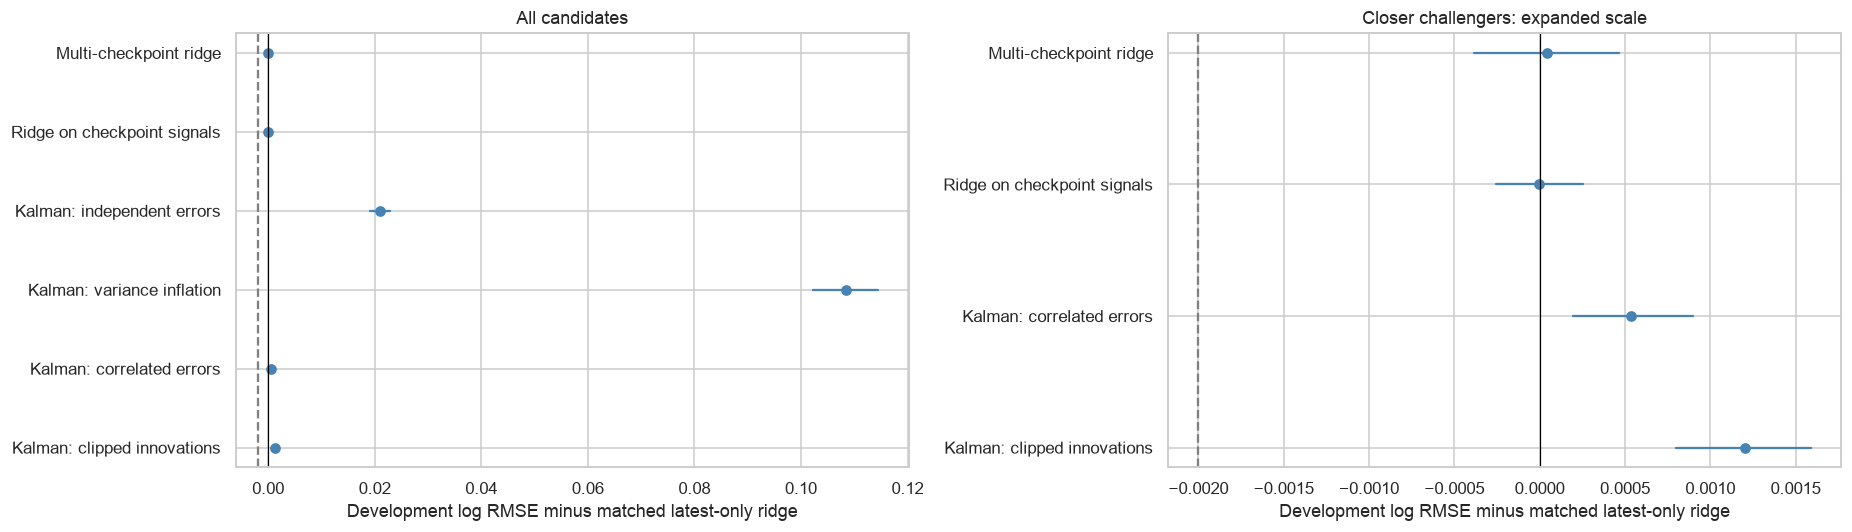

**Development decision:** Incumbent tuned daily + 15:30 ridge. The table preserves the practical, annual-stability, WAPE and paired-interval conditions separately.

In [6]:
gate=pd.read_csv(RUN/'selection_gate.csv');intervals=pd.read_csv(RUN/'paired_intervals.csv')
display(gate)
display(intervals[(intervals.period=='development')&intervals.metric.eq('rmse_log')])
fig,axes=plt.subplots(1,2,figsize=(17,5))
part=intervals[(intervals.period=='development')&intervals.metric.eq('rmse_log')&intervals.reference.eq('latest_ridge')]
closer=part[~part.candidate.isin(['kalman_diagonal','kalman_inflated'])]
for ax,rows,title in [(axes[0],part,'All candidates'),(axes[1],closer,'Closer challengers: expanded scale')]:
    for i,row in enumerate(rows.itertuples()):
        ax.plot([row.lower,row.upper],[i,i],color='steelblue');ax.scatter(row.difference,i,color='steelblue')
    ax.set_yticks(range(len(rows)),[NAMES[x] for x in rows.candidate]);ax.axvline(0,color='black',linewidth=.8)
    ax.axvline(-.002,color='grey',linestyle='--');ax.set(title=title,xlabel='Development log RMSE minus matched latest-only ridge');ax.invert_yaxis()
plt.tight_layout();plt.show()
selected_method=decision['selected_method']
display(Markdown('**Development decision:** '+NAMES[selected_method]+'. The table preserves the practical, annual-stability, WAPE and paired-interval conditions separately.'))

## Is the filter uncertainty empirically calibrated?

A Kalman posterior variance describes uncertainty under its fitted linear measurement model. Our auction residuals need not be Gaussian or homoskedastic, component estimates are fitted, and reconstruction clips extreme predictions. The robust and variance-inflated versions further alter the standard assumptions.

We therefore evaluate empirical coverage of central 80% and 95% Gaussian bands in **log space**, centred at the actually reconstructed forecast. These diagnostics assess the proposed variance approximation; they are not calibrated prediction-interval guarantees. Coverage is reported by time and year. No test-label scaling is fitted to improve it.

This distinction matters for later control work: a filter that produces a shrinking variance has not automatically supplied a reliable auction-liquidity distribution. Any subsequent interval calibration would need its own prior-only design and checking.

,checkpoint,coverage_80,coverage_95,mean_sd_log,standardized_rmse
method,,,,,
Kalman: correlated errors,15:30,0.884687,0.959092,0.484704,0.942730
Kalman: independent errors,15:30,0.733578,0.883337,0.334390,1.427836
Kalman: variance inflation,15:30,0.786036,0.912872,0.459483,1.230936
Kalman: clipped innovations,15:30,0.883796,0.958781,0.483455,0.946525


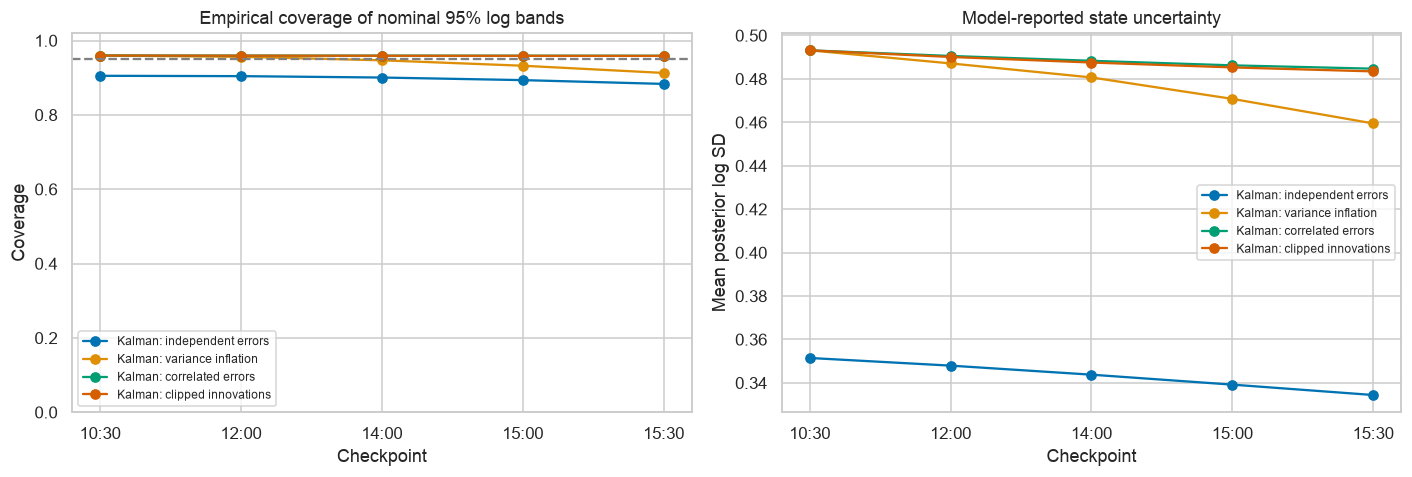

In [7]:
uncertainty=pd.read_csv(RUN/'uncertainty_diagnostics.csv')
ud=uncertainty[uncertainty.year.isin(k.DEV)].groupby(['method','checkpoint'])[['coverage_80','coverage_95','mean_sd_log','standardized_rmse']].mean().reset_index()
display(ud[ud.checkpoint.eq('15:30')].set_index('method').rename(index=NAMES))
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for method in k.FAMILIES:
    rows=ud[ud.method.eq(method)].set_index('checkpoint').loc[k.TIMES]
    axes[0].plot(k.TIMES,rows.coverage_95,marker='o',label=NAMES[method])
    axes[1].plot(k.TIMES,rows.mean_sd_log,marker='o',label=NAMES[method])
axes[0].axhline(.95,color='grey',linestyle='--');axes[0].set(title='Empirical coverage of nominal 95% log bands',ylabel='Coverage',ylim=(0,1.02))
axes[1].set(title='Model-reported state uncertainty',ylabel='Mean posterior log SD')
for ax in axes:ax.legend(fontsize=8);ax.set_xlabel('Checkpoint')
plt.tight_layout();plt.show()

## Missing observations and subgroup checks

With a missing current checkpoint, a sequential method can retain useful earlier measurements; the latest-only model and incumbent instead use daily fallback. The complete-checkpoint subset shows whether the headline comparison is driven by that policy difference. No zero-volume observation is invented for missing data.

Liquidity groups use prior information and event groups are disjoint, with quarterly expiry taking precedence over monthly expiry and month-end. Group scores are descriptive, not a new routing rule. Sparse event dates and multiple comparisons limit subgroup conclusions.

In [8]:
availability=pd.read_csv(RUN/'availability_sensitivity.csv')
avail_summary=availability[availability.year.isin(k.DEV)].groupby(['sample','method'])[['rmse_log','wape','aggregate_bias']].mean()
display(avail_summary)
segments=pd.read_csv(RUN/'annual_segment_metrics.csv')
seg_summary=segments[segments.year.isin(k.DEV)].groupby(['dimension','segment','method'])[['rmse_log','wape','aggregate_bias']].mean()
display(seg_summary.loc['liquidity'].reset_index().pivot(index='segment',columns='method',values='rmse_log'))

rmse_log     wape  \
sample                      method                                      
all_checkpoints_available   daily                   0.461912 0.348680   
                            incumbent_1530          0.452420 0.339790   
                            kalman_correlated       0.453044 0.340131   
                            kalman_diagonal         0.473462 0.358803   
                            kalman_inflated         0.560984 0.440177   
                            kalman_robust           0.453710 0.340751   
                            latest_ridge            0.452523 0.339582   
                            multi_checkpoint_ridge  0.452583 0.339927   
                            signal_stack_ridge      0.452529 0.339711   
latest_checkpoint_available daily                   0.463817 0.348719   
                            incumbent_1530          0.454441 0.339830   
                            kalman_correlated       0.455035 0.340171   
                            kalman_diagonal         0.475452 0.358842   
                            kalman_inflated         0.562994 0.440213   
                            kalman_robust           0.455705 0.340791   
                            latest_ridge            0.454502 0.339622   
                            multi_checkpoint_ridge  0.454543 0.339966   
                            signal_stack_ridge      0.454497 0.339751   
latest_checkpoint_missing   daily                   1.236626 0.918569   
                            incumbent_1530          1.236626 0.918569   
                            kalman_correlated       1.236626 0.918569   
                            kalman_diagonal         1.236626 0.918569   
                            kalman_inflated         1.236626 0.918569   
                            kalman_robust           1.236626 0.918569   
                            latest_ridge            1.236626 0.918569   
                            multi_checkpoint_ridge  1.236626 0.918569   
                            signal_stack_ridge      1.236626 0.918569   

                                                    aggregate_bias  
sample                      method                                  
all_checkpoints_available   daily                        -0.153069  
                            incumbent_1530               -0.122315  
                            kalman_correlated            -0.123881  
                            kalman_diagonal              -0.107290  
                            kalman_inflated              -0.042736  
                            kalman_robust                -0.124989  
                            latest_ridge                 -0.124006  
                            multi_checkpoint_ridge       -0.120192  
                            signal_stack_ridge           -0.125078  
latest_checkpoint_available daily                        -0.153118  
                            incumbent_1530               -0.122367  
                            kalman_correlated            -0.123932  
                            kalman_diagonal              -0.107342  
                            kalman_inflated              -0.042791  
                            kalman_robust                -0.125039  
                            latest_ridge                 -0.124058  
                            multi_checkpoint_ridge       -0.120243  
                            signal_stack_ridge           -0.125127  
latest_checkpoint_missing   daily                        -0.642663  
                            incumbent_1530               -0.642663  
                            kalman_correlated            -0.642663  
                            kalman_diagonal              -0.642663  
                            kalman_inflated              -0.642663  
                            kalman_robust                -0.642663  
                            latest_ridge                 -0.642663  
                            multi_checkpoint_ridge       -0.642663  
  

method,daily,incumbent_1530,kalman_correlated,kalman_diagonal,kalman_inflated,kalman_robust,latest_ridge,multi_checkpoint_ridge,signal_stack_ridge
segment,,,,,,,,,
high,0.436352,0.421372,0.422312,0.441901,0.524218,0.423225,0.421879,0.421720,0.421853
low,0.521391,0.523813,0.523691,0.546654,0.644258,0.523869,0.522899,0.523049,0.522833
mid,0.437561,0.420978,0.421928,0.440713,0.524018,0.422880,0.421559,0.421705,0.421651


## A fixed stock-day example of the sequential forecast path

The example uses 3 March 2025 and three stocks chosen by evenly spaced ranks of their daily forecast on that date. It is chosen for an illustrative range of stock sizes, not for a favorable prediction error. The realised auction is drawn for retrospective comparison only; the filtering code never receives it.

A simple filter can move strongly when several correlated signals point in the same direction. The correlated variant can recognise their overlap. Earlier times can still be less accurate than later ones on an individual day; a particular path is not an adoption test.

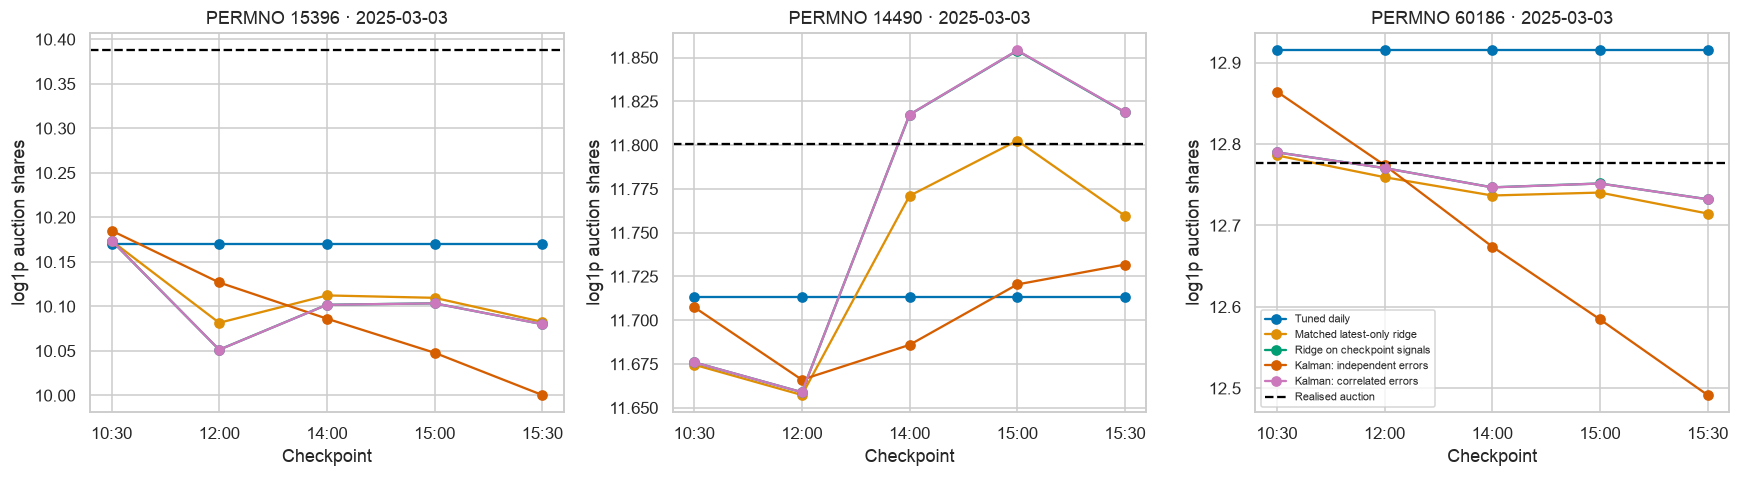

In [9]:
con=duckdb.connect()
frame=con.execute("SELECT * FROM read_parquet(?) WHERE date=DATE '2025-03-03' ORDER BY daily_forecast,permno",[str(RUN/'predictions/forecasts_2025.parquet')]).df()
example=frame.iloc[((np.arange(3)+.5)*len(frame)/3).astype(int)]
fig,axes=plt.subplots(1,3,figsize=(16,4.5))
for ax,(_,row) in zip(axes,example.iterrows()):
    for method in ['daily','latest_ridge','signal_stack_ridge','kalman_diagonal','kalman_correlated']:
        values=[np.log1p(row[f'{method}_{tag}']) for tag in k.TAGS]
        ax.plot(k.TIMES,values,marker='o',label=NAMES[method])
    ax.axhline(np.log1p(row.auction_volume),color='black',linestyle='--',label='Realised auction')
    ax.set(title=f'PERMNO {row.permno} · 2025-03-03',ylabel='log1p auction shares',xlabel='Checkpoint')
axes[-1].legend(fontsize=7);plt.tight_layout();plt.show()
con.close()

## Interpretation and limits

The correlated Kalman filter reaches development log RMSE **0.45530**, much closer to the incumbent **0.45471** than the diagonal filter at **0.47570**. Its corresponding 2025 scores are **0.40570** versus incumbent **0.40418**. Multi-checkpoint ridge (**0.45481**) and signal-stack ridge (**0.45476**) also fail to establish an incremental development improvement. Earlier checkpoint information does not supply a qualifying gain in this tested design.

At 15:30, the diagonal filter's nominal 95% log bands cover about **88.3%** of development outcomes, versus **95.9%** for the correlated filter. However, the correlated filter's nominal 80% bands cover about **88.5%**, showing that near-nominal 95% coverage alone does not establish a calibrated Gaussian predictive distribution.

The controls separate three questions: whether current checkpoint information helps the daily forecast, whether earlier checkpoints add information beyond the latest snapshot, and whether a Kalman covariance structure is a useful way to combine those signals. A Kalman filter does not create information absent from its inputs.

The observation-error correlation and the independent-versus-correlated comparisons address overlap in the learned signals. They do not prove a unique cause for every performance difference. Alternative measurement designs, nonlinear observation models, more granular inputs, different uncertainty models and newer periods remain untested here.

The deliberately frozen component design makes calibration genuinely out of time and avoids moving the measurement model between calibration and evaluation. It sacrifices the most recent six months of component-fitting labels relative to the incumbent. The matched latest-only and multi-checkpoint models use that same cutoff. The close matched-control score helps assess this difference, but does not make the two fitting protocols identical.

Calibration uses a single global linear loading and covariance, with complete historical measurement rows for covariance estimation. Missingness, cross-stock heteroskedasticity and sparse tail events can affect its suitability. State variance is checked empirically rather than assumed calibrated. No smoothing, evaluation-label assimilation, new execution simulation or future unseen period is included.

In [10]:
# Produce a concise numerical conclusion from the executed tables.
d=development[development.checkpoint.eq('15:30')].set_index('method')
c=confirmation[confirmation.checkpoint.eq('15:30')].set_index('method')
lines=['| Method | Development log RMSE | Development WAPE | 2025 log RMSE |',
       '| --- | ---: | ---: | ---: |']
for method in ['incumbent_1530','latest_ridge','multi_checkpoint_ridge','signal_stack_ridge',*k.FAMILIES]:
    lines.append(f'| {NAMES[method]} | {d.loc[method,"rmse_log"]:.5f} | {100*d.loc[method,"wape"]:.2f}% | {c.loc[method,"rmse_log"]:.5f} |')
display(Markdown('\n'.join(lines)))
# Keep results, decision and empirical coverage together in an exportable research record.
result={'selected_method':selected_method,'selected_display':NAMES[selected_method],
        'development_1530':d.reset_index().to_dict('records'),
        'confirmation_1530':c.reset_index().to_dict('records'),
        'source_code_sha256':k.sha(ROOT/'notebooks/explore_intraday_kalman.py'),
        'new_training_years':k.YEARS,'independent_history_rows':int(history_checks.rows.sum()),
        'annual_metric_rows':len(annual),'filter_prefixes':k.TIMES,'mathematical_checks':math_checks}
k.write_json(RUN/'notebook_verification.json',result)
source_files=[ROOT/'notebooks/explore_intraday_kalman.py',RUN/'plan.json',*sorted((RUN/'models').glob('*.json'))]
pd.DataFrame([{'path':str(p.relative_to(ROOT)),'sha256':k.sha(p),'bytes':p.stat().st_size} for p in source_files]).to_csv(RUN/'fitted_source_manifest.csv',index=False)

| Method | Development log RMSE | Development WAPE | 2025 log RMSE |
| --- | ---: | ---: | ---: |
| Incumbent tuned daily + 15:30 ridge | 0.45471 | 33.98% | 0.40418 |
| Matched latest-only ridge | 0.45477 | 33.96% | 0.40517 |
| Multi-checkpoint ridge | 0.45481 | 34.00% | 0.40544 |
| Ridge on checkpoint signals | 0.45476 | 33.98% | 0.40565 |
| Kalman: independent errors | 0.47570 | 35.88% | 0.42507 |
| Kalman: variance inflation | 0.56318 | 44.02% | 0.50487 |
| Kalman: correlated errors | 0.45530 | 34.02% | 0.40570 |
| Kalman: clipped innovations | 0.45597 | 34.08% | 0.40680 |

## Review point and next work

Read the executed conclusion and gate together. A qualifying replacement must improve on both the matched latest-only ridge and the existing tuned daily plus 15:30 pairing. Without that evidence, retain the incumbent and keep the sequential variants in the research record.

The next control-problem ideation remains deferred at the user's request. Any later execution exercise should use these measured forecast and uncertainty limitations, rather than assume Kalman output is superior or its variance is a calibrated fill-risk model.

- [Daily summary](09_daily_model_results_and_decision.ipynb) and [intraday checkpoint 6](10_intraday_forecasts_controls_and_pairings.ipynb).
- [Executable fitting and filtering implementation](../notebooks/explore_intraday_kalman.py).
- [New experiment artifacts](../outputs/experiments/33_intraday_kalman/).
- [Original state-space filtering paper](https://www.cs.unc.edu/~welch/kalman/media/pdf/Kalman1960.pdf).